# 04 – Export clean data for Power BI + dashboard preview

Exports the `sales` view to `data/sales_clean.csv` (Power BI source together with `data/rfm_segments.csv`)
and draws a static preview of the two Power BI pages. Build steps: `dashboard/POWERBI_STEPS.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.image import imread
from sqlalchemy import text
from db import get_engine

engine = get_engine("olist")
sales = pd.read_sql(text("SELECT * FROM sales"), engine)
sales.to_csv("../data/sales_clean.csv", index=False)
rfm = pd.read_csv("../data/rfm_segments.csv")

# one row per delivered + reviewed order: delivery time, late / on time, review score
delivery_reviews = pd.read_sql(text("""
    SELECT o.order_id, c.customer_state,
           DATEDIFF(o.order_delivered_customer_date, o.order_purchase_timestamp) AS delivery_days,
           CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 'Late' ELSE 'On time' END AS delivery_status,
           r.review_score
    FROM orders o
    JOIN customers c     ON o.customer_id = c.customer_id
    JOIN order_reviews r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL"""), engine)
delivery_reviews.to_csv("../data/delivery_reviews.csv", index=False)
print(f"sales_clean.csv: {len(sales):,} rows | rfm_segments.csv: {len(rfm):,} rows | "
      f"delivery_reviews.csv: {len(delivery_reviews):,} rows")

sales_clean.csv: 110,197 rows | rfm_segments.csv: 93,358 rows | delivery_reviews.csv: 96,353 rows


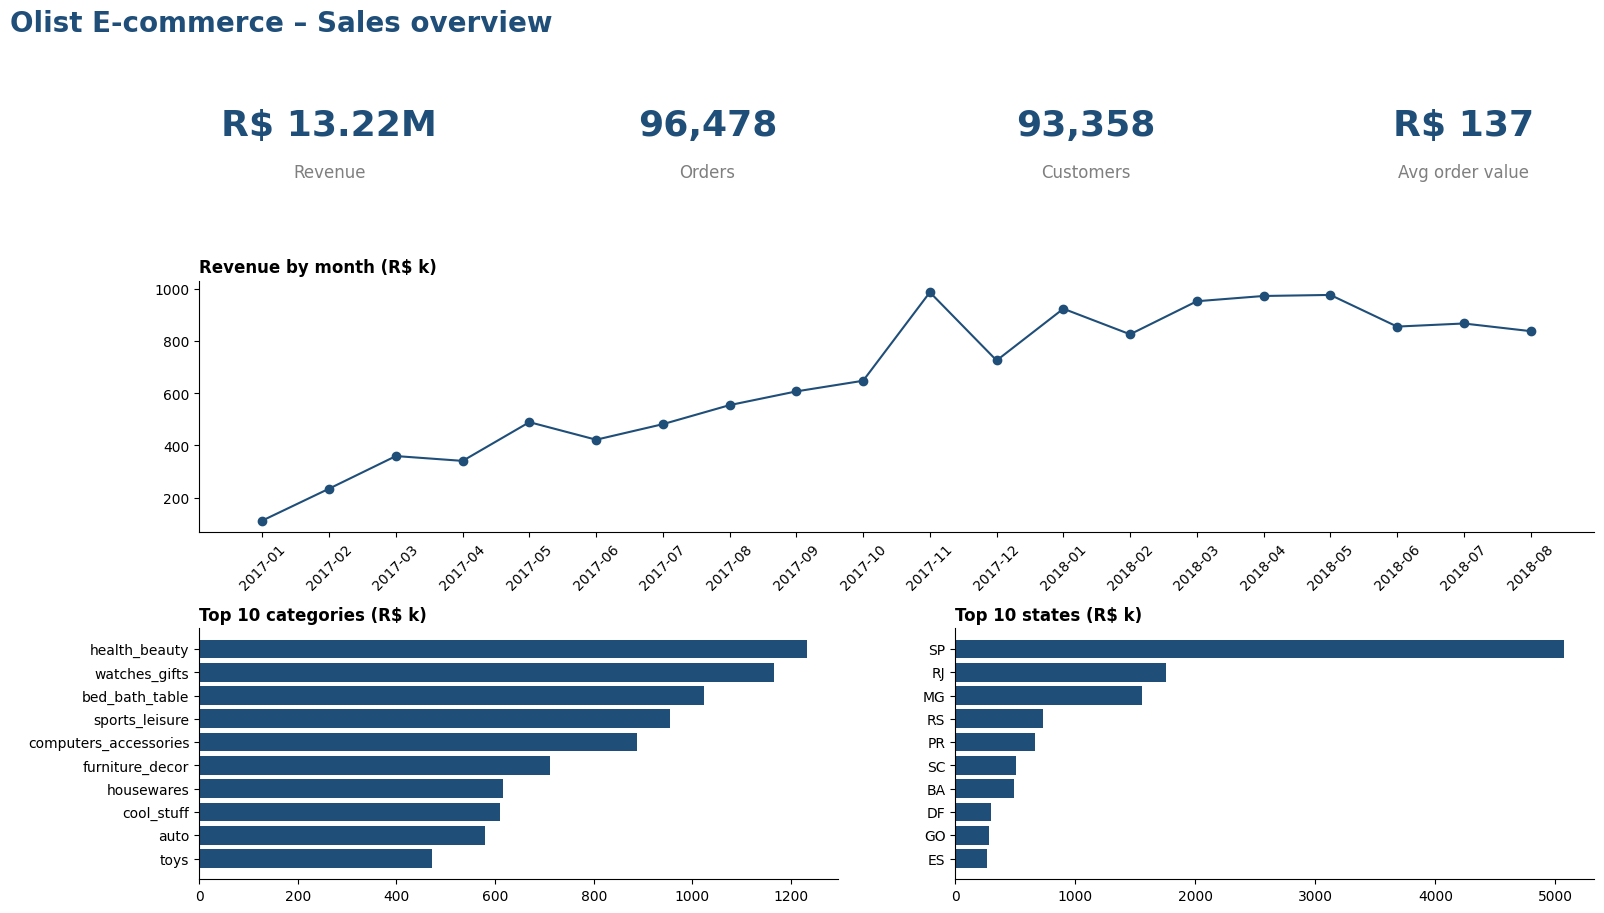

In [2]:
BLUE, LIGHT, RED, GREY = "#1f4e79", "#9dc3e6", "#c0504d", "#7f7f7f"
orders_n = sales.order_id.nunique()
kpis = [("Revenue", f"R$ {sales.price.sum() / 1e6:.2f}M"), ("Orders", f"{orders_n:,}"),
        ("Customers", f"{sales.customer_unique_id.nunique():,}"),
        ("Avg order value", f"R$ {sales.price.sum() / orders_n:.0f}")]

fig = plt.figure(figsize=(18, 10))
gs = gridspec.GridSpec(3, 4, height_ratios=[0.3, 1, 1], hspace=0.5, wspace=0.45)
fig.suptitle("Olist E-commerce – Sales overview", fontsize=20, fontweight="bold", x=0.02, ha="left", color=BLUE)
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0.5, 0.65, value, ha="center", fontsize=26, fontweight="bold", color=BLUE)
    ax.text(0.5, 0.1, label, ha="center", fontsize=12, color=GREY)

m = sales[(sales.month >= "2017-01") & (sales.month <= "2018-08")].groupby("month").price.sum() / 1000
ax = fig.add_subplot(gs[1, :])
ax.plot(m.index, m.values, marker="o", color=BLUE); ax.set_title("Revenue by month (R$ k)", loc="left", fontweight="bold")
ax.tick_params(axis="x", rotation=45); ax.spines[["top", "right"]].set_visible(False)

c = sales.groupby("category").price.sum().nlargest(10).sort_values() / 1000
ax = fig.add_subplot(gs[2, 0:2]); ax.barh(c.index, c.values, color=BLUE)
ax.set_title("Top 10 categories (R$ k)", loc="left", fontweight="bold"); ax.spines[["top", "right"]].set_visible(False)
s = sales.groupby("customer_state").price.sum().nlargest(10).sort_values() / 1000
ax = fig.add_subplot(gs[2, 2:]); ax.barh(s.index, s.values, color=BLUE)
ax.set_title("Top 10 states (R$ k)", loc="left", fontweight="bold"); ax.spines[["top", "right"]].set_visible(False)
plt.savefig("../dashboard/page1_sales_overview.png", dpi=120, bbox_inches="tight")
plt.show()

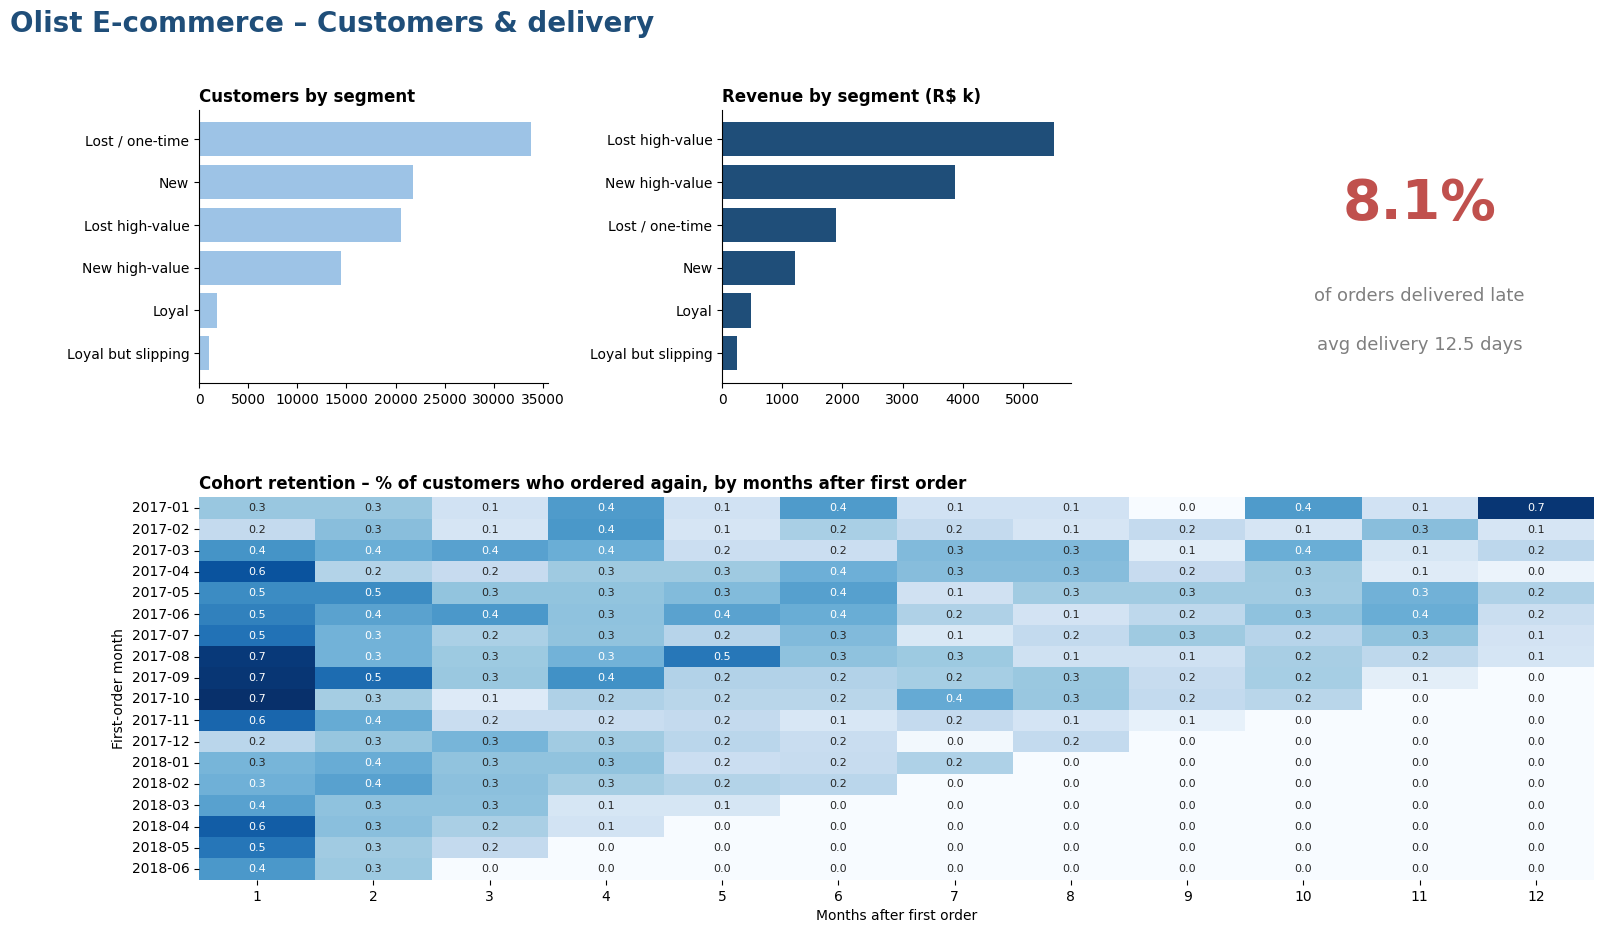

In [3]:
d = sales.drop_duplicates("order_id")
late_pct = d.is_late.mean()
seg = rfm.groupby("segment").agg(customers=("customer_unique_id", "size"), revenue=("monetary", "sum"))

fig = plt.figure(figsize=(18, 10))
gs = gridspec.GridSpec(2, 3, height_ratios=[1, 1.4], hspace=0.35, wspace=0.5)
fig.suptitle("Olist E-commerce – Customers & delivery", fontsize=20, fontweight="bold", x=0.02, ha="left", color=BLUE)
s1 = seg.sort_values("customers")
ax = fig.add_subplot(gs[0, 0]); ax.barh(s1.index, s1.customers, color=LIGHT)
ax.set_title("Customers by segment", loc="left", fontweight="bold"); ax.spines[["top", "right"]].set_visible(False)
s2 = seg.sort_values("revenue")
ax = fig.add_subplot(gs[0, 1]); ax.barh(s2.index, s2.revenue / 1000, color=BLUE)
ax.set_title("Revenue by segment (R$ k)", loc="left", fontweight="bold"); ax.spines[["top", "right"]].set_visible(False)
ax = fig.add_subplot(gs[0, 2]); ax.axis("off")
ax.text(0.5, 0.6, f"{late_pct:.1%}", ha="center", fontsize=40, fontweight="bold", color=RED)
ax.text(0.5, 0.3, "of orders delivered late", ha="center", fontsize=13, color=GREY)
ax.text(0.5, 0.12, f"avg delivery {d.delivery_days.mean():.1f} days", ha="center", fontsize=13, color=GREY)
import seaborn as sns
o = sales.groupby(["customer_unique_id", "order_id"]).purchase_time.min().reset_index()
o["order_month"] = pd.to_datetime(o.purchase_time).dt.to_period("M")
o["cohort"] = o.groupby("customer_unique_id").order_month.transform("min")
o["months_since"] = (o.order_month - o.cohort).apply(lambda x: x.n)
cnt = o.groupby(["cohort", "months_since"]).customer_unique_id.nunique().unstack(fill_value=0)
ret = (cnt.div(cnt[0], axis=0) * 100).loc["2017-01":"2018-06", 1:12]
ax = fig.add_subplot(gs[1, :])
sns.heatmap(ret, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar=False, annot_kws={"size": 8})
ax.set_title("Cohort retention – % of customers who ordered again, by months after first order",
             loc="left", fontweight="bold")
ax.set_xlabel("Months after first order"); ax.set_ylabel("First-order month")
plt.savefig("../dashboard/page2_customers_delivery.png", dpi=120, bbox_inches="tight")
plt.show()